# Proyecto E-commerce: Limpieza y Análisis Exploratorio

Este notebook se conecta a la base de datos `ecommerce_portfolio` en PostgreSQL,
limpia los problemas típicos de datos reales (nulos, duplicados, formatos
inconsistentes) y hace un análisis exploratorio para dejar todo listo
para el dashboard de Power BI.

**Flujo del notebook:**
1. Conexión a PostgreSQL
2. Carga de las 4 tablas
3. Limpieza: clientes, productos, pedidos, detalle_pedidos
4. Análisis exploratorio: ventas por categoría, top clientes, tendencia mensual
5. Exportar tablas limpias (CSV y de vuelta a PostgreSQL) para conectar Power BI


## 1. Importar librerías

In [5]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import matplotlib.pyplot as plt


pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 5)


## 2. Conexión a PostgreSQL

Ajusta usuario, contraseña, host y puerto según tu configuración local
(los mismos valores que usaste en `generar_datos.py`).

In [4]:
DB_USER = "soporte"
DB_PASSWORD = "contraseña"
DB_HOST = "localhost"
DB_PORT = "5432"
DB_NAME = "ecommerce_portfolio"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

# Prueba rápida de conexión
with engine.connect() as conn:
    print("Conexión exitosa a", DB_NAME)


Conexión exitosa a ecommerce_portfolio


## 3. Cargar las 4 tablas en DataFrames

In [3]:
clientes = pd.read_sql("SELECT * FROM clientes", engine)
productos = pd.read_sql("SELECT * FROM productos", engine)
pedidos = pd.read_sql("SELECT * FROM pedidos", engine)
detalle = pd.read_sql("SELECT * FROM detalle_pedidos", engine)

print("clientes:", clientes.shape)
print("productos:", productos.shape)
print("pedidos:", pedidos.shape)
print("detalle_pedidos:", detalle.shape)


clientes: (310, 6)
productos: (60, 5)
pedidos: (1200, 5)
detalle_pedidos: (3558, 5)


In [4]:
clientes.head()

,cliente_id,nombre,email,ciudad,pais,fecha_registro
0,1,María Marcela Torres,buitragostiven@example.org,Cimitarra,Colombia,2023-10-25
1,2,Luz Moreno,None,Guarne,Colombia,2026-01-24
2,3,Edith Judith Guerrero Cardona,edwin02@example.net,Concepción,Colombia,2025-02-15
3,4,Carlos Yepes,sandra61@example.com,Puerto Concordia,Colombia,2026-03-31
4,5,Rubén Ariza,cardozomyriam@example.net,Sipí,Colombia,2026-05-09


## 4. Exploración inicial: ¿qué tan "sucios" están los datos?

Antes de limpiar, siempre conviene diagnosticar: nulos, duplicados,
valores inconsistentes.

In [5]:
print("Nulos por columna en clientes:")
print(clientes.isnull().sum())
print()
print("Filas duplicadas en clientes (exactas):", clientes.duplicated(subset=['nombre','email','ciudad']).sum())
print()
print("Valores únicos de categoría en productos:")
print(productos['categoria'].unique())
print()
print("Ejemplos de formatos de fecha en pedidos:")
print(pedidos['fecha_pedido'].dropna().sample(10, random_state=1).tolist())


Nulos por columna en clientes:
cliente_id         0
nombre             0
email             13
ciudad             0
pais               0
fecha_registro     0
dtype: int64

Filas duplicadas en clientes (exactas): 10

Valores únicos de categoría en productos:
['HOGAR' 'ELECTRÓNICA' 'deportes' 'Ropa' 'Deportes' 'Hogar' 'DEPORTES'
 'JUGUETES' 'Electrónica' 'libros' 'ROPA' 'hogar' 'LIBROS' 'Libros'
 'Juguetes' 'juguetes' 'ropa']

Ejemplos de formatos de fecha en pedidos:
['08-03-2026', '10/07/2026', '21-05-2026', '03/02/2026', '2025-12-06', '2026/02/21', '14/09/2025', '2026/08/26', '2025-11-13', '10/06/2026']


## 5. Limpieza: clientes

- Quitamos duplicados exactos (mismo cliente cargado dos veces)
- Marcamos los emails nulos en vez de inventarlos (no rellenamos con datos falsos)


In [6]:
clientes_limpio = clientes.drop_duplicates(subset=['nombre', 'email', 'ciudad']).copy()

clientes_limpio['email_faltante'] = clientes_limpio['email'].isnull()

print(f"Clientes originales: {len(clientes)} -> Clientes tras quitar duplicados: {len(clientes_limpio)}")
print(f"Clientes con email faltante: {clientes_limpio['email_faltante'].sum()}")


Clientes originales: 310 -> Clientes tras quitar duplicados: 300
Clientes con email faltante: 13


## 6. Limpieza: productos

Normalizamos la categoría (mayúsculas/minúsculas mezcladas) a un formato
consistente tipo "Título".

In [7]:
productos_limpio = productos.copy()
productos_limpio['categoria'] = productos_limpio['categoria'].str.strip().str.title()

print("Categorías antes:", sorted(productos['categoria'].unique()))
print("Categorías después:", sorted(productos_limpio['categoria'].unique()))


Categorías antes: ['DEPORTES', 'Deportes', 'ELECTRÓNICA', 'Electrónica', 'HOGAR', 'Hogar', 'JUGUETES', 'Juguetes', 'LIBROS', 'Libros', 'ROPA', 'Ropa', 'deportes', 'hogar', 'juguetes', 'libros', 'ropa']
Categorías después: ['Deportes', 'Electrónica', 'Hogar', 'Juguetes', 'Libros', 'Ropa']


## 7. Limpieza: pedidos

Las fechas vienen en al menos 4 formatos distintos (simulando distintos
sistemas de origen). Usamos `pd.to_datetime` con `format='mixed'`, que
detecta el formato de cada fila automáticamente.

In [8]:
pedidos_limpio = pedidos.copy()
pedidos_limpio['fecha_pedido'] = pd.to_datetime(
    pedidos_limpio['fecha_pedido'], format='mixed', dayfirst=False, errors='coerce'
)

print(f"Fechas que no se pudieron convertir: {pedidos_limpio['fecha_pedido'].isnull().sum()}")
pedidos_limpio[['pedido_id', 'fecha_pedido']].head()


Fechas que no se pudieron convertir: 41


,pedido_id,fecha_pedido
0,1,2026-04-21
1,2,2025-12-15
2,3,2026-08-28
3,4,2026-07-18
4,5,2025-05-10


## 8. Limpieza: detalle_pedidos

Eliminamos líneas con cantidad = 0 (errores de captura, no representan
una venta real).

In [9]:
print(f"Líneas con cantidad = 0: {(detalle['cantidad'] == 0).sum()}")

detalle_limpio = detalle[detalle['cantidad'] > 0].copy()
detalle_limpio['total_linea'] = detalle_limpio['cantidad'] * detalle_limpio['precio_unitario']

print(f"Detalle original: {len(detalle)} -> Detalle limpio: {len(detalle_limpio)}")


Líneas con cantidad = 0: 29
Detalle original: 3558 -> Detalle limpio: 3529


## 9. Unir las tablas en un dataset analítico

Creamos una tabla "ancha" combinando pedidos + detalle + productos + clientes,
lista para analizar y para exportar a Power BI.

In [11]:
ventas = (
    detalle_limpio
    .merge(pedidos_limpio, on='pedido_id', how='left')
    .merge(productos_limpio[['producto_id', 'nombre_producto', 'categoria']], on='producto_id', how='left')
    .merge(clientes_limpio[['cliente_id', 'nombre', 'ciudad']], on='cliente_id', how='left')
)

# Solo nos interesan pedidos completados para el análisis de ventas
ventas_completadas = ventas[ventas['estado'] == 'Completado'].copy()

print(ventas_completadas.shape)
ventas_completadas.head()


(2158, 14)


,detalle_id,pedido_id,producto_id,cantidad,precio_unitario,total_linea,cliente_id,fecha_pedido,estado,metodo_pago,nombre_producto,categoria,nombre,ciudad
0,1,1,54,1,30782.38,30782.38,173,2026-04-21,Completado,Nequi,Deserunt Cupiditate,Juguetes,Diego Becerra,Altos del Rosario
1,2,1,6,3,38966.09,116898.27,173,2026-04-21,Completado,Nequi,Unde Minus,Deportes,Diego Becerra,Altos del Rosario
2,3,1,31,1,475057.81,475057.81,173,2026-04-21,Completado,Nequi,Dolor Corrupti,Libros,Diego Becerra,Altos del Rosario
3,4,2,43,4,384614.56,1538458.24,103,2025-12-15,Completado,PSE,Esse Itaque,Deportes,David Juan Vargas,Puerto Nare
4,5,2,8,2,482048.70,964097.40,103,2025-12-15,Completado,PSE,Enim Quia,Hogar,David Juan Vargas,Puerto Nare


## 10. Análisis: ventas por categoría

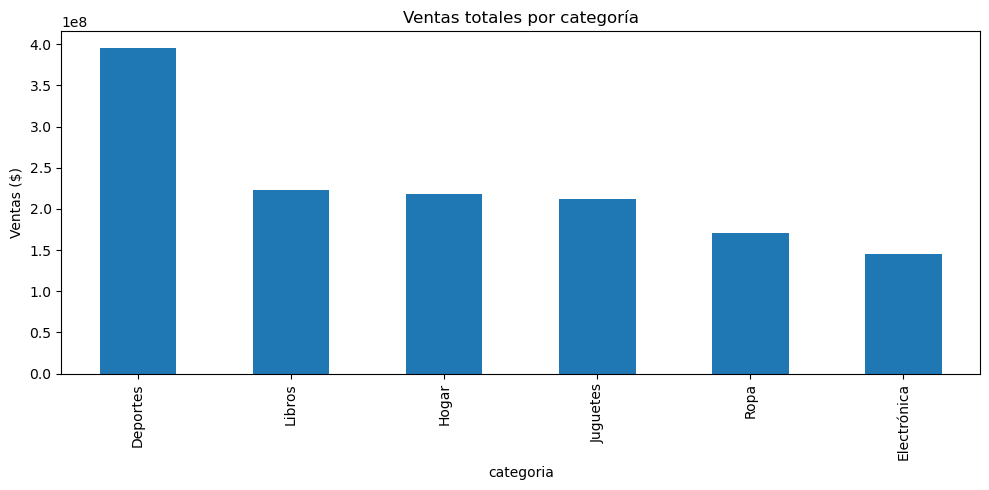

categoria
Deportes       3.958264e+08
Libros         2.225656e+08
Hogar          2.182189e+08
Juguetes       2.120635e+08
Ropa           1.712820e+08
Electrónica    1.452463e+08
Name: total_linea, dtype: float64

In [12]:

ventas_por_categoria = (
    ventas_completadas.groupby('categoria')['total_linea']
    .sum()
    .sort_values(ascending=False)
)

ventas_por_categoria.plot(kind='bar', title='Ventas totales por categoría')
plt.ylabel('Ventas ($)')
plt.tight_layout()
plt.show()

ventas_por_categoria


## 11. Análisis: top 10 clientes por valor de compra

In [13]:
top_clientes = (
    ventas_completadas.groupby(['cliente_id', 'nombre'])['total_linea']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_clientes


cliente_id  nombre                       
142         Dary Jaimes                      16039787.25
197         Isabel Forero                    15027623.71
111         Elvira Natalia Rico              14197829.82
128         Mayra Ana Gallego                13173453.70
62          Luz Constanza Gaitán Carvajal    13149576.89
46          Isabel Vanessa Beltrán           12594503.37
284         Yésica Patricia González         12077240.41
269         Lorena Romero                    11779955.08
53          Enrique Correa Martínez          11669393.99
84          Lorena Álvarez                   11497693.60
Name: total_linea, dtype: float64

## 12. Análisis: tendencia mensual de ventas

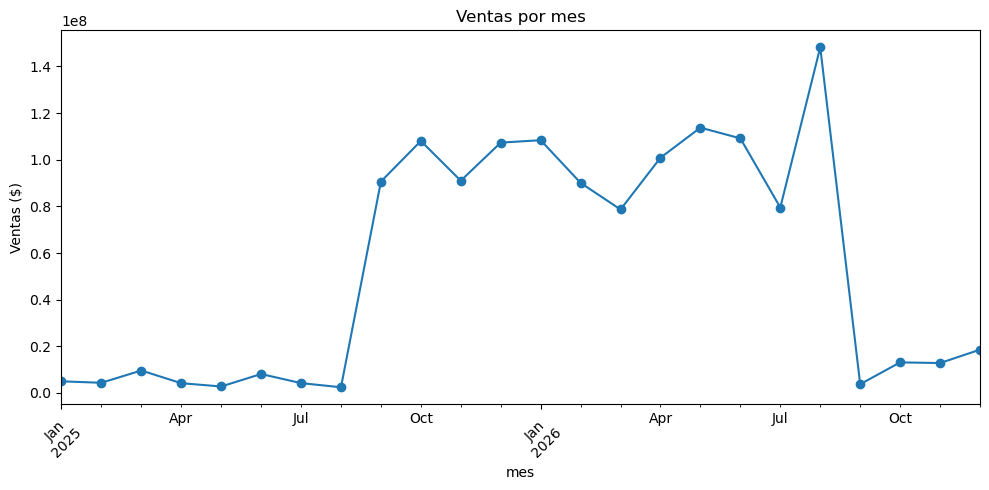

In [14]:
ventas_completadas['mes'] = ventas_completadas['fecha_pedido'].dt.to_period('M')

tendencia_mensual = ventas_completadas.groupby('mes')['total_linea'].sum()

tendencia_mensual.plot(kind='line', marker='o', title='Ventas por mes')
plt.ylabel('Ventas ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [17]:
ventas_completadas['mes'] = ventas_completadas['mes'].astype(str)

## 13. Concentración de clientes (regla 80/20)

¿Qué porcentaje de clientes genera qué porcentaje de las ventas?

In [15]:
ventas_por_cliente = (
    ventas_completadas.groupby('cliente_id')['total_linea'].sum().sort_values(ascending=False)
)

acumulado_pct = ventas_por_cliente.cumsum() / ventas_por_cliente.sum() * 100
clientes_pct = (np.arange(1, len(ventas_por_cliente) + 1) / len(ventas_por_cliente)) * 100

pct_clientes_80 = (acumulado_pct <= 80).sum() / len(ventas_por_cliente) * 100
print(f"El {pct_clientes_80:.1f}% de los clientes genera el 80% de las ventas.")


El 54.4% de los clientes genera el 80% de las ventas.


## 14. Exportar tablas limpias

Dos opciones para conectar Power BI:
1. **CSV** — más simple, Power BI importa el archivo directamente
2. **Nuevas tablas en PostgreSQL** — más profesional, Power BI se conecta
   en vivo a la base de datos

Hacemos ambas.

In [ ]:
# Opción 1: CSV
clientes_limpio.to_csv("clientes_limpio.csv", index=False)
productos_limpio.to_csv("productos_limpio.csv", index=False)
pedidos_limpio.to_csv("pedidos_limpio.csv", index=False)
ventas_completadas.to_csv("ventas_completas.csv", index=False)

print("CSVs exportados en la carpeta actual.")


In [18]:
# Opción 2: de vuelta a PostgreSQL, en tablas nuevas con prefijo "limpio_"
clientes_limpio.to_sql("limpio_clientes", engine, if_exists="replace", index=False)
productos_limpio.to_sql("limpio_productos", engine, if_exists="replace", index=False)
pedidos_limpio.to_sql("limpio_pedidos", engine, if_exists="replace", index=False)
ventas_completadas.to_sql("limpio_ventas", engine, if_exists="replace", index=False)

print("Tablas limpias escritas en PostgreSQL: limpio_clientes, limpio_productos, limpio_pedidos, limpio_ventas")


Tablas limpias escritas en PostgreSQL: limpio_clientes, limpio_productos, limpio_pedidos, limpio_ventas


## Siguiente paso

Con `limpio_ventas` (o los CSV) ya puedes abrir Power BI Desktop y:
1. Conectarte a PostgreSQL (Obtener datos → Base de datos → PostgreSQL) o importar los CSV
2. Traer `limpio_ventas` como tabla de hechos
3. Construir las visualizaciones: ventas en el tiempo, top categorías, top clientes
